# Data Cleaning and Collinearity

**Data.** Daily weather at 98 airports, 2005-01-01 to 2014-12-31: 3652 days x 98 airports x 22 variables.

This notebook does two things and nothing else:

**Part A: Cleaning.** We turn the raw `weather` data frame into `weather_cleaned`, one row per airport per day.
Every change is listed below and every value we remove is recorded in `clean_log`.

| Step | What we do to the data |
|---|---|
| A1 | Reshape from 2156 wide columns (`AIRPORT_Variable`) to one row per airport-day, and give variables short names |
| A2 | Precipitation: `"T"` (trace, < 0.01 in) becomes `0`, with a `precip_trace` 0/1 flag kept; `""` becomes `NA` |
| A3 | Events: text like `"Fog-Rain"` is split into 0/1 columns (`fog`, `rain`, `snow`, ...); `""` means no event |
| A4 | Values outside physical bounds (e.g. 621,207 F, 1000 mph wind, cloud cover -398) become `NA` |
| A5 | Temperature consistency: if Min > Max, all three temperatures become `NA`; if Mean is outside [Min, Max], Mean becomes `NA` |
| A6 | Temperature spikes: a value more than 35 F away from **both** neighbouring days in the same direction is listed in `temp_spikes` and then set to `NA` |

We do **not** fill in (impute) missing values here. They stay `NA`.

**Part B: Collinearity.** How strongly are the candidate predictor variables related to each other?
The temperatures (`tmax`, `tmean`, `tmin`) are what we will predict, so they are left out of this part.

At the end we make `weather_cleaned_subset` (the 15 target airports only) and save everything to `data/weather_clean.rda`.

In [27]:
suppressPackageStartupMessages(library(tidyverse))
options(width = 140, dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))
fig <- function(w = 10, h = 6) options(repr.plot.width = w, repr.plot.height = h)
fig()

load("../data/weather.rda")   # creates `weather`: a data.frame whose row names are the dates P
cat("Raw data:", nrow(weather), "rows (days) x", ncol(weather), "columns\n")

Raw data: 3652 rows (days) x 2156 columns


# Part A: Cleaning

## A1. Reshape to one row per airport-day

The raw data has one row per day and 2156 columns named `AIRPORT_Variable`, for example `DTW_Max.TemperatureF`.
We first check that every airport has the same 22 variables, then:

1. Move the dates from the row names into a `date` column.
2. Stack the columns into a long table (`date`, `airport`, `var`, `raw`) where `raw` is the original value **as text**.
   We use text because some columns are factors, and converting a factor straight to a number gives its level index, not its value.
3. Rename the variables to short names (table below).

In [28]:
weather <- weather |>
  rownames_to_column("date") |>
  mutate(date = ymd(date)) |>
  as_tibble()
stopifnot(!anyNA(weather$date), all(diff(weather$date) == 1))   # every day present, in order

col_info <- tibble(column = names(weather)[-1]) |>
  mutate(airport = str_extract(column, "^[A-Z]{3}"),
         var     = str_remove(column, "^[A-Z]{3}_"),
         class   = map_chr(column, \(cc) class(weather[[cc]])[1]))
airports <- unique(col_info$airport)
cat(length(airports), "airports x", n_distinct(col_info$var), "variables\n")
stopifnot(all(count(col_info, airport)$n == 22))

# How each variable is stored in R. Precipitation and Events are stored inconsistently across airports.
col_info |> count(var, class) |> pivot_wider(names_from = class, values_from = n, values_fill = 0)

98 airports x 22 variables


var,integer,character,factor,numeric
<chr>,<int>,<int>,<int>,<int>
CloudCover,98,0,0,0
Events,0,1,97,0
Max.Dew.PointF,98,0,0,0
Max.Gust.SpeedMPH,98,0,0,0
Max.Humidity,98,0,0,0
Max.Sea.Level.PressureIn,0,0,0,98
Max.TemperatureF,98,0,0,0
Max.VisibilityMiles,98,0,0,0
Max.Wind.SpeedMPH,98,0,0,0


In [29]:
var_names <- c(
  Max.TemperatureF = "tmax", Mean.TemperatureF = "tmean", Min.TemperatureF = "tmin",
  Max.Dew.PointF = "dew_max", MeanDew.PointF = "dew_mean", Min.DewpointF = "dew_min",
  Max.Humidity = "hum_max", Mean.Humidity = "hum_mean", Min.Humidity = "hum_min",
  Max.Sea.Level.PressureIn = "slp_max", Mean.Sea.Level.PressureIn = "slp_mean",
  Min.Sea.Level.PressureIn = "slp_min",
  Max.VisibilityMiles = "vis_max", Mean.VisibilityMiles = "vis_mean", Min.VisibilityMiles = "vis_min",
  Max.Wind.SpeedMPH = "wind_max", Mean.Wind.SpeedMPH = "wind_mean", Max.Gust.SpeedMPH = "gust_max",
  PrecipitationIn = "precip", CloudCover = "cloud", Events = "events", WindDirDegrees = "wind_dir"
)
tibble(original = names(var_names), new_name = var_names) |> print(n = Inf)

long_raw <- weather |>
  mutate(across(-date, as.character)) |>
  pivot_longer(-date, names_to = c("airport", "var"),
               names_pattern = "^([A-Z]{3})_(.*)$", values_to = "raw") |>
  mutate(var = unname(var_names[var]), raw = str_trim(raw))
stopifnot(!anyNA(long_raw$var), nrow(long_raw) == nrow(weather) * 98 * 22)
cat("Long table:", nrow(long_raw), "rows = 3652 days x 98 airports x 22 variables\n")

# A tibble: 22 × 2
   original                  new_name 
   <chr>                     <chr>    
 1 Max.TemperatureF          tmax     
 2 Mean.TemperatureF         tmean    
 3 Min.TemperatureF          tmin     
 4 Max.Dew.PointF            dew_max  
 5 MeanDew.PointF            dew_mean 
 6 Min.DewpointF             dew_min  
 7 Max.Humidity              hum_max  
 8 Mean.Humidity             hum_mean 
 9 Min.Humidity              hum_min  
10 Max.Sea.Level.PressureIn  slp_max  
11 Mean.Sea.Level.PressureIn slp_mean 
12 Min.Sea.Level.PressureIn  slp_min  
13 Max.VisibilityMiles       vis_max  
14 Mean.VisibilityMiles      vis_mean 
15 Min.VisibilityMiles       vis_min  
16 Max.Wind.SpeedMPH         wind_max 
17 Mean.Wind.SpeedMPH        wind_mean
18 Max.Gust.SpeedMPH         gust_max 
19 PrecipitationIn           precip   
20 CloudCover                cloud    
21 Events                    events   
22 WindDirDegrees            wind_dir 
Long table: 7873712 rows = 3652 days x 98 air

## A2. Precipitation and other non-numeric values

Below are all values (other than Events) that are not plain numbers.
Only precipitation has them: `"T"` means a trace of rain (< 0.01 in) and `""` means nothing was recorded.

**What we do:** `"T"` becomes `0` and we keep a separate `precip_trace` column (1 = trace day). `""` becomes `NA`.
Every other value is converted to a number.

In [30]:
long_raw |>
  filter(var != "events", !is.na(raw), is.na(suppressWarnings(as.numeric(raw)))) |>
  count(var, raw)

var,raw,n
<chr>,<chr>,<int>
precip,,4
precip,T,40406


In [31]:
trace <- long_raw |>
  filter(var == "precip") |>
  transmute(date, airport, precip_trace = as.integer(raw == "T"))

values_long <- long_raw |>
  filter(var != "events") |>
  mutate(value = suppressWarnings(as.numeric(if_else(var == "precip" & raw == "T", "0", raw)))) |>
  select(date, airport, var, value)

cat("Trace-precipitation airport-days set to 0:", sum(trace$precip_trace, na.rm = TRUE), "\n")

Trace-precipitation airport-days set to 0: 40406 


## A3. Events

`events` is text such as `"Fog-Rain-Snow"`. An empty string means no event that day; `NA` means not recorded.

**What we do:** make one 0/1 column per event type. A day with `"Fog-Rain"` gets `fog = 1`, `rain = 1`, and 0 for the rest.
If the original value was `NA`, all event columns are `NA`.

In [32]:
event_types <- c("Fog", "Rain", "Snow", "Thunderstorm", "Hail", "Tornado")
events <- long_raw |> filter(var == "events") |> select(date, airport, raw)
for (e in event_types) events[[str_to_lower(e)]] <- as.integer(str_detect(events$raw, e))
events <- select(events, -raw)

cat("Share of airport-days with each event type:\n")
events |> summarise(across(-c(date, airport), \(x) round(mean(x, na.rm = TRUE), 3)))

Share of airport-days with each event type:


fog,rain,snow,thunderstorm,hail,tornado
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.093,0.299,0.081,0.101,0.001,0


## Missingness in the raw data

Before removing anything, how much is already missing? These numbers are for the raw data (after A2),
so later we can see how much cleaning added.

In [33]:
missing_raw <- values_long |>
  group_by(airport, var) |>
  summarise(pct_na = 100 * mean(is.na(value)), .groups = "drop")

cat("% missing by variable (averaged over airports):\n")
missing_raw |> group_by(var) |> summarise(pct_na = round(mean(pct_na), 2)) |> arrange(desc(pct_na)) |> print(n = Inf)

cat("\nAirports with the most missing data (% over all variables):\n")
missing_raw |> group_by(airport) |> summarise(pct_na = round(mean(pct_na), 1)) |> slice_max(pct_na, n = 10)

% missing by variable (averaged over airports):
# A tibble: 21 × 2
   var       pct_na
   <chr>      <dbl>
 1 gust_max    6.5 
 2 cloud       0.53
 3 dew_max     0.53
 4 dew_mean    0.53
 5 dew_min     0.53
 6 slp_max     0.53
 7 slp_mean    0.53
 8 slp_min     0.53
 9 vis_max     0.53
10 vis_mean    0.53
11 vis_min     0.53
12 precip      0.43
13 hum_max     0.11
14 hum_mean    0.11
15 hum_min     0.11
16 wind_max    0.09
17 wind_mean   0.09
18 tmax        0.08
19 tmean       0.08
20 tmin        0.08
21 wind_dir    0.03

Airports with the most missing data (% over all variables):


airport,pct_na
<chr>,<dbl>
TTN,15.4
ORD,11.9
MYR,3.3
HFD,1.8
UNV,1.8
FOE,1.5
LCK,1.5
OAK,1.2
BMG,0.8


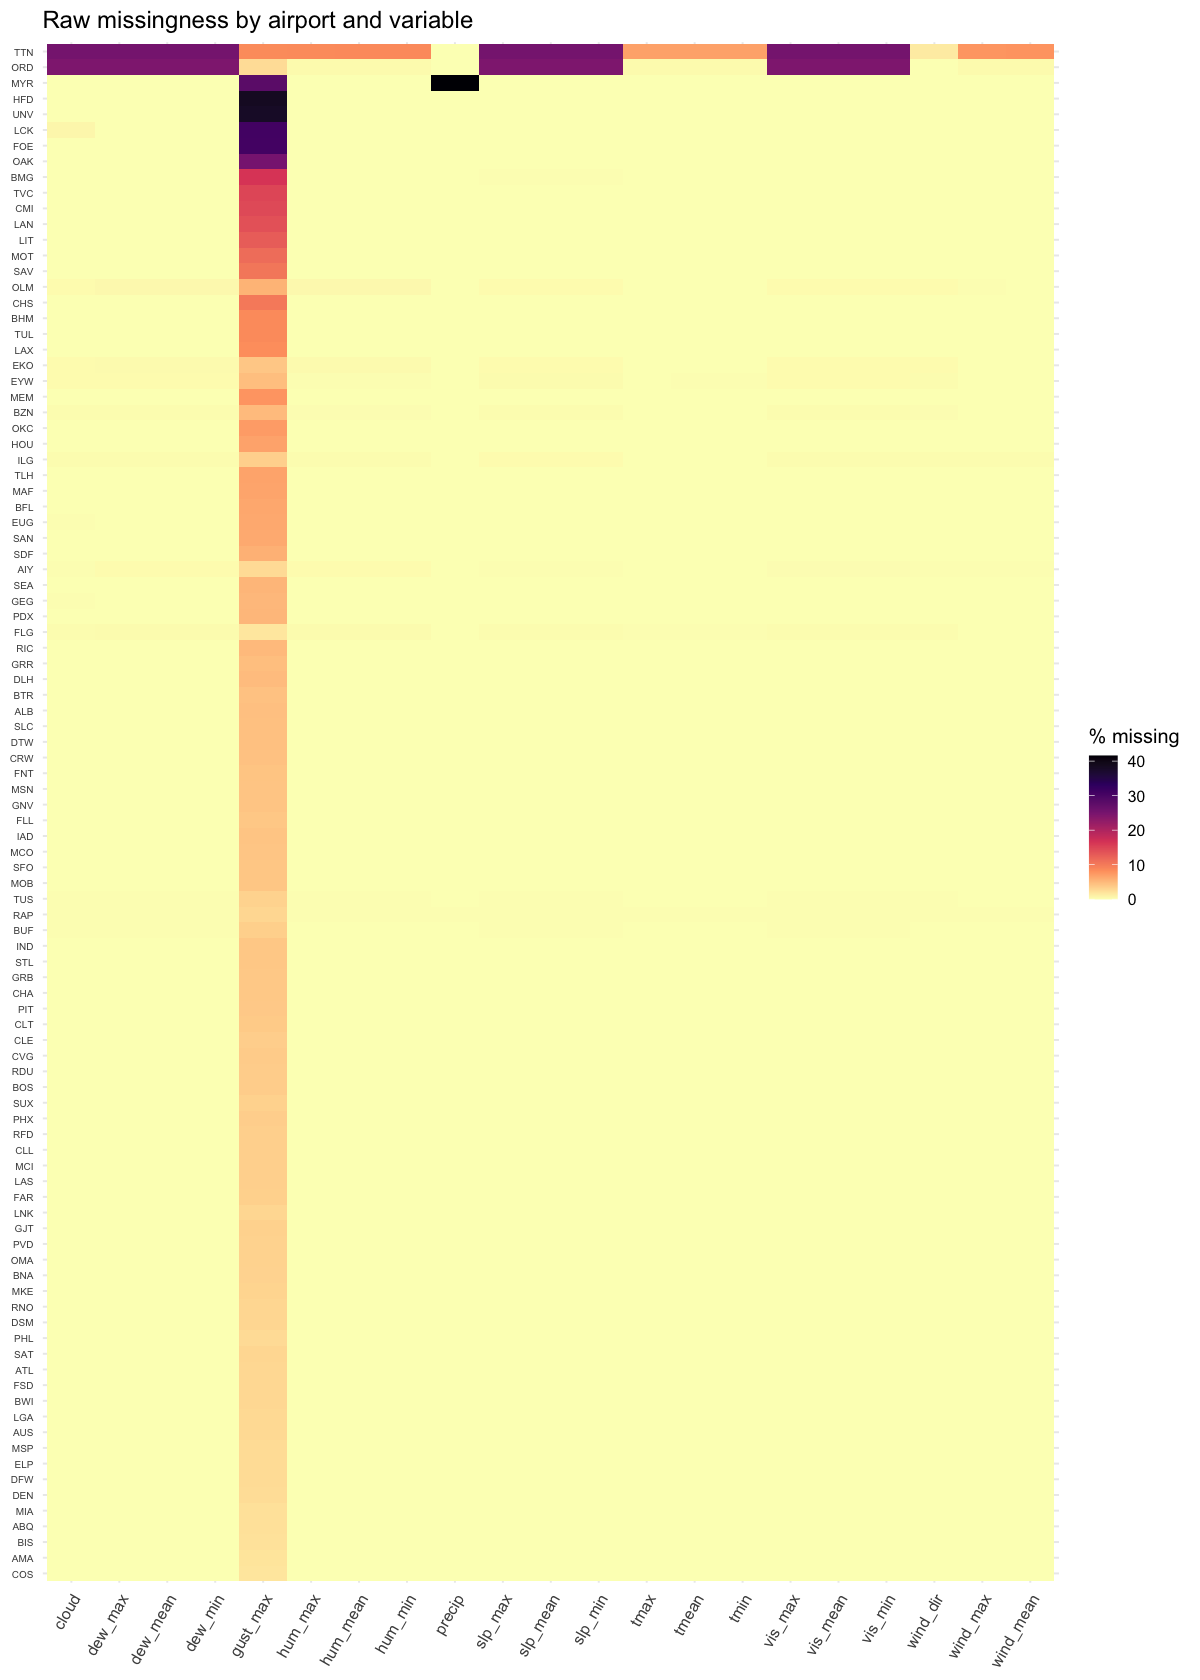

In [34]:
fig(10, 14)
missing_raw |>
  mutate(airport = fct_reorder(airport, pct_na, mean)) |>
  ggplot(aes(var, airport, fill = pct_na)) +
  geom_tile() +
  scale_fill_viridis_c(option = "magma", direction = -1, name = "% missing") +
  labs(x = NULL, y = NULL, title = "Raw missingness by airport and variable") +
  theme(axis.text.x = element_text(angle = 60, hjust = 1), axis.text.y = element_text(size = 6))

## A4. Values outside physical bounds

The table below shows each variable's smallest and largest values. Several are clearly errors or placeholder codes:
temperatures of 621,207 F and -1000 F, wind speeds of 1000 mph, cloud cover of -398 (the scale is 0-8 eighths),
a dew point of -135 F, and a wind direction of -1 (likely a "calm/variable" code).

In [35]:
fig()
values_long |>
  group_by(var) |>
  summarise(min    = min(value, na.rm = TRUE),
            q0.1   = quantile(value, 0.001, na.rm = TRUE),
            median = median(value, na.rm = TRUE),
            q99.9  = quantile(value, 0.999, na.rm = TRUE),
            max    = max(value, na.rm = TRUE)) |>
  print(n = Inf)

# A tibble: 21 × 6
   var           min  q0.1 median  q99.9      max
   <chr>       <dbl> <dbl>  <dbl>  <dbl>    <dbl>
 1 cloud      -398     0      4     8         8  
 2 dew_max     -27    -9     50    80        88  
 3 dew_mean    -32   -15     44    77        81  
 4 dew_min    -135   -23     38    74        79  
 5 gust_max      0     7     23    74      1000  
 6 hum_max       0    14     88   100       100  
 7 hum_mean      0     9     66    97       100  
 8 hum_min       0     3     44    93       100  
 9 precip        0     0      0     3.36    999  
10 slp_max      28.9  29.5   30.1  30.8      31.2
11 slp_mean     28.6  29.3   30.0  30.7      31.0
12 slp_min      28.0  29.1   29.9  30.6      30.9
13 tmax        -15     1     70   109    621207  
14 tmean       -23    -7     60    98       106  
15 tmin      -1000   -18     48    87    461159  
16 vis_max       0     3     10    10        20  
17 vis_mean      0     1     10    10        20  
18 vis_min       0     0      8

**What we do:** any value outside the bounds below becomes `NA` and is added to `clean_log`.
The bounds are deliberately wide (physically possible in the US), so only clear errors are removed.

In [36]:
bounds <- tribble(
  ~var,        ~lo,   ~hi,
  "tmax",      -60,   130,
  "tmean",     -60,   130,
  "tmin",      -60,   130,
  "dew_max",   -70,    95,
  "dew_mean",  -70,    95,
  "dew_min",   -70,    95,
  "hum_max",     0,   100,
  "hum_mean",    0,   100,
  "hum_min",     0,   100,
  "slp_max",  27.5,  31.5,
  "slp_mean", 27.5,  31.5,
  "slp_min",  27.5,  31.5,
  "vis_max",     0,    20,
  "vis_mean",    0,    20,
  "vis_min",     0,    20,
  "wind_max",    0,   150,
  "wind_mean",   0,   100,
  "gust_max",    0,   200,
  "precip",      0,    15,
  "cloud",       0,     8,
  "wind_dir",    0,   360
)

values_long <- values_long |>
  left_join(bounds, by = "var") |>
  mutate(out_of_bounds = coalesce(value < lo | value > hi, FALSE))

clean_log <- values_long |>
  filter(out_of_bounds) |>
  transmute(date, airport, var, value, reason = "A4: out of bounds")

values_long <- values_long |>
  mutate(value = if_else(out_of_bounds, NA_real_, value)) |>
  select(date, airport, var, value)

cat("Values set to NA in A4:", nrow(clean_log), "\n\n")
clean_log |> count(var, sort = TRUE)

Values set to NA in A4: 1846 



var,n
<chr>,<int>
wind_dir,1813
gust_max,18
wind_max,4
tmax,3
tmin,3
cloud,2
dew_min,2
precip,1


### Build the cleaned table

Now we turn the long table back into one row per airport-day with one column per variable,
and add the `precip_trace` and event columns. This is `weather_cleaned`.

In [37]:
weather_cleaned <- values_long |>
  pivot_wider(names_from = var, values_from = value) |>
  left_join(trace,  by = c("date", "airport")) |>
  left_join(events, by = c("date", "airport")) |>
  arrange(airport, date)

cat(nrow(weather_cleaned), "rows (98 airports x 3652 days) x", ncol(weather_cleaned), "columns\n")
glimpse(weather_cleaned)

357896 rows (98 airports x 3652 days) x 30 columns
Rows: 357,896
Columns: 30
$ date         <date> 2005-01-01, 2005-01-02, 2005-01-03, 2005-01-04, 2005-01-05, 2005-01-06, 2005-01-07, 2005-01-08, 2005-01-09, 2005-01-…
$ airport      <chr> "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ", "ABQ"…
$ tmax         <dbl> 54, 45, 48, 50, 42, 39, 39, 55, 57, 61, 57, 42, 46, 46, 51, 54, 55, 57, 60, 57, 55, 55, 55, 55, 57, 50, 44, 48, 50, 3…
$ tmean        <dbl> 45, 41, 42, 42, 37, 30, 32, 44, 48, 50, 50, 37, 37, 38, 40, 42, 42, 44, 46, 42, 45, 48, 42, 42, 46, 44, 40, 40, 40, 3…
$ tmin         <dbl> 36, 37, 37, 33, 26, 21, 24, 34, 39, 39, 44, 32, 28, 30, 28, 30, 30, 30, 33, 28, 35, 39, 28, 30, 35, 39, 36, 32, 30, 3…
$ dew_max      <dbl> 35, 38, 45, 43, 30, 23, 21, 29, 33, 36, 35, 34, 19, 15, 16, 17, 22, 27, 26, 29, 29, 27, 28, 41, 38, 41, 43, 31, 36, 3…
$ dew_mean     <dbl> 31, 34, 40, 38, 21, 20, 18, 26, 30, 33, 29, 21, 13, 12, 11, 14

## A5. Temperature consistency

For each airport-day we need Min <= Mean <= Max.

**What we do:**
* If **Min > Max**, we can't tell which value is wrong, so all three temperatures become `NA`.
* If **Mean is outside [Min, Max]**, only Mean becomes `NA`.

In [38]:
temp_cols <- c("tmax", "tmean", "tmin")

# Helper: turn rows of weather_cleaned into clean_log entries for the given temperature columns
log_temps <- function(df, cols, reason) {
  df |>
    select(date, airport, all_of(cols)) |>
    pivot_longer(all_of(cols), names_to = "var", values_to = "value") |>
    mutate(reason = reason)
}

bad_order <- weather_cleaned |> filter(tmin > tmax)
cat("Days with Min > Max:", nrow(bad_order), "\n")
print(select(bad_order, date, airport, tmax, tmean, tmin))
clean_log <- bind_rows(clean_log, log_temps(bad_order, temp_cols, "A5: min > max"))
weather_cleaned <- weather_cleaned |>
  mutate(bad = coalesce(tmin > tmax, FALSE),
         across(all_of(temp_cols), \(x) if_else(bad, NA_real_, x))) |>
  select(-bad)

bad_mean <- weather_cleaned |> filter(tmean > tmax | tmean < tmin)
cat("\nDays with Mean outside [Min, Max]:", nrow(bad_mean), "\n")
print(select(bad_mean, date, airport, tmax, tmean, tmin))
clean_log <- bind_rows(clean_log, log_temps(bad_mean, "tmean", "A5: mean outside [min, max]"))
weather_cleaned <- weather_cleaned |>
  mutate(tmean = if_else(coalesce(tmean > tmax | tmean < tmin, FALSE), NA_real_, tmean))

Days with Min > Max: 2 
# A tibble: 2 × 5
  date       airport  tmax tmean  tmin
  <date>     <chr>   <dbl> <dbl> <dbl>
1 2012-06-10 RDU         0    33    65
2 2013-07-23 TUS        73    85    75

Days with Mean outside [Min, Max]: 10 
# A tibble: 10 × 5
   date       airport  tmax tmean  tmin
   <date>     <chr>   <dbl> <dbl> <dbl>
 1 2008-10-01 DTW        58    64    45
 2 2005-06-30 FOE        66    72    64
 3 2007-10-13 FOE        61    62    57
 4 2011-03-23 IAD        68    23    45
 5 2010-03-07 OAK        64    84    46
 6 2006-08-09 OKC        87    93    81
 7 2005-06-09 OLM        75     0    51
 8 2006-04-16 RAP        57    60    45
 9 2007-03-18 RAP        39    56    33
10 2006-12-03 RIC        48    54    40


## A6. Temperature spikes

Some temperatures pass the A4 bounds but look odd for that day, e.g. 136 F at MYR in February.
We flag a temperature when it is more than **35 F** above (or below) **both** the day before and the day after
at the same airport. A single bad reading looks like this; a real weather change usually moves the temperature
to a new level that lasts more than one day.

**What we do:** list the spikes in `temp_spikes`, then set each flagged temperature to `NA` in `weather_cleaned`
and record it in `clean_log`. Only the flagged series is blanked; the other two temperatures for that day are kept.

In [39]:
spike_thr <- 35

temp_spikes <- weather_cleaned |>
  select(date, airport, all_of(temp_cols)) |>
  pivot_longer(all_of(temp_cols), names_to = "var", values_to = "value") |>
  group_by(airport, var) |>
  arrange(date, .by_group = TRUE) |>
  mutate(prev_day = lag(value), next_day = lead(value)) |>
  ungroup() |>
  filter(coalesce((value - prev_day >  spike_thr & value - next_day >  spike_thr) |
                  (value - prev_day < -spike_thr & value - next_day < -spike_thr), FALSE)) |>
  select(date, airport, var, prev_day, value, next_day)

cat("Temperature spikes found (left in the data):", nrow(temp_spikes), "\n")
cat("Of these, at target airports:",
    sum(temp_spikes$airport %in% c("ABQ", "ATL", "BOS", "DEN", "DFW", "DLH", "DTW", "EYW",
                                   "IAD", "LAN", "LAX", "SEA", "SFO", "SLC", "TVC")), "\n\n")
temp_spikes |> arrange(airport, date) |> print(n = Inf)


# Remove the flagged spikes: set each one to NA in weather_cleaned and record it in clean_log
clean_log <- bind_rows(clean_log,
                       temp_spikes |> transmute(date, airport, var, value, reason = "A6: spike"))

for (v in temp_cols) {
  spike_days <- temp_spikes |>
    filter(var == v) |>
    distinct(date, airport) |>
    mutate(is_spike = TRUE)

  weather_cleaned <- weather_cleaned |>
    left_join(spike_days, by = c("date", "airport")) |>
    mutate(!!v := if_else(coalesce(is_spike, FALSE), NA_real_, .data[[v]])) |>
    select(-is_spike)
}

cat("Spike temperatures set to NA:", nrow(temp_spikes), "\n")


Temperature spikes found (left in the data): 5 
Of these, at target airports: 0 

# A tibble: 5 × 6
  date       airport var   prev_day value next_day
  <date>     <chr>   <chr>    <dbl> <dbl>    <dbl>
1 2008-12-15 AMA     tmax        65    15       55
2 2008-07-02 CMI     tmin        55    -1       61
3 2008-09-24 CMI     tmin        57     0       57
4 2009-01-19 CMI     tmax        25    99       30
5 2014-02-28 MYR     tmean       43    86       46
Spike temperatures set to NA: 5 


## Cleaning summary

How many values each step removed, and the % missing for each variable before and after cleaning.

In [40]:
cat("Values set to NA by each step:\n")
clean_log |> count(reason) |> print()

cat("\nAll temperature values removed (any step):\n")
clean_log |> filter(var %in% temp_cols) |> arrange(airport, date) |> print(n = Inf)

Values set to NA by each step:
# A tibble: 4 × 2
  reason                          n
  <chr>                       <int>
1 A4: out of bounds            1846
2 A5: mean outside [min, max]    10
3 A5: min > max                   6
4 A6: spike                       5

All temperature values removed (any step):
# A tibble: 27 × 5
   date       airport var    value reason                     
   <date>     <chr>   <chr>  <dbl> <chr>                      
 1 2008-12-15 AMA     tmax      15 A6: spike                  
 2 2008-07-02 CMI     tmin      -1 A6: spike                  
 3 2008-09-24 CMI     tmin       0 A6: spike                  
 4 2009-01-19 CMI     tmax      99 A6: spike                  
 5 2009-06-02 DEN     tmax   54112 A4: out of bounds          
 6 2009-06-02 DEN     tmin  461159 A4: out of bounds          
 7 2008-10-01 DTW     tmean     64 A5: mean outside [min, max]
 8 2005-06-30 FOE     tmean     72 A5: mean outside [min, max]
 9 2007-10-13 FOE     tmean     62 A5: mea

In [41]:
pct_na_after <- weather_cleaned |>
  summarise(across(all_of(bounds$var), \(x) 100 * mean(is.na(x)))) |>
  pivot_longer(everything(), names_to = "var", values_to = "pct_na_after")

missing_raw |>
  group_by(var) |>
  summarise(pct_na_before = mean(pct_na)) |>
  left_join(pct_na_after, by = "var") |>
  mutate(added = pct_na_after - pct_na_before,
         across(where(is.numeric), \(x) round(x, 3))) |>
  arrange(desc(pct_na_after)) |>
  print(n = Inf)

# A tibble: 21 × 4
   var       pct_na_before pct_na_after added
   <chr>             <dbl>        <dbl> <dbl>
 1 gust_max          6.50         6.51  0.005
 2 wind_dir          0.031        0.537 0.507
 3 cloud             0.534        0.534 0.001
 4 dew_max           0.531        0.531 0    
 5 dew_mean          0.531        0.531 0    
 6 dew_min           0.531        0.531 0.001
 7 slp_max           0.527        0.527 0    
 8 slp_mean          0.527        0.527 0    
 9 slp_min           0.527        0.527 0    
10 vis_max           0.526        0.526 0    
11 vis_mean          0.526        0.526 0    
12 vis_min           0.526        0.526 0    
13 precip            0.425        0.426 0    
14 hum_max           0.111        0.111 0    
15 hum_mean          0.111        0.111 0    
16 hum_min           0.111        0.111 0    
17 wind_mean         0.089        0.089 0    
18 wind_max          0.087        0.088 0.001
19 tmean             0.075        0.079 0.004
20 tmax        

# Part B: Collinearity

Here we look at how closely the candidate **predictor** variables move together. Variables that carry nearly the same
information cause problems when used together in a regression (unstable coefficients, inflated standard errors).

What is included and why:
* **The temperatures `tmax`, `tmean` and `tmin` are excluded.** They are the response variables we will predict,
  so their collinearity with the predictors is not a problem to diagnose here.
* Dew point, humidity, pressure, visibility, wind, precipitation and cloud cover are included.
* Wind direction is an angle (359 degrees is next to 1 degree), so instead of the raw angle we use
  `wind_ns = cos(angle)` (+1 = from the north) and `wind_ew = sin(angle)` (+1 = from the east).
* The 0/1 event columns are left out.

These correlations pool all 98 airports and all days, so part of the correlation (for example dew point with the seasons)
comes from variables rising and falling together through the year.

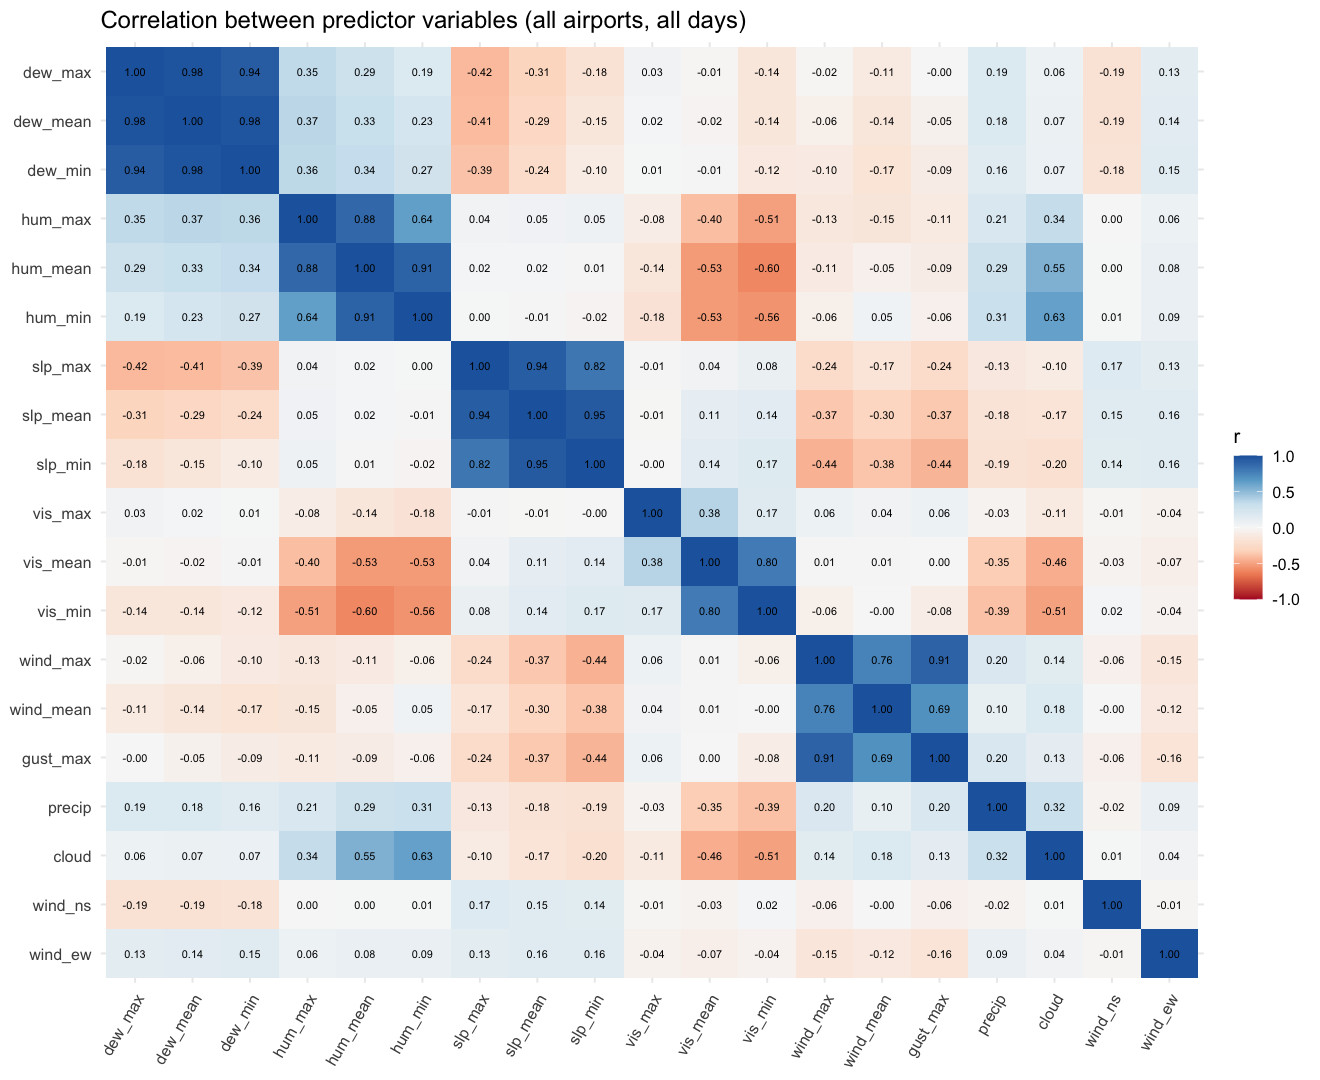

In [42]:
# Temperatures (tmax, tmean, tmin) are the response variables, so they are not included
collin_vars <- c("dew_max", "dew_mean", "dew_min",
                 "hum_max", "hum_mean", "hum_min", "slp_max", "slp_mean", "slp_min",
                 "vis_max", "vis_mean", "vis_min", "wind_max", "wind_mean", "gust_max",
                 "precip", "cloud", "wind_ns", "wind_ew")

collin_df <- weather_cleaned |>
  mutate(wind_ns = cos(wind_dir * pi / 180),
         wind_ew = sin(wind_dir * pi / 180)) |>
  select(all_of(collin_vars))

# Pairwise correlation: each pair uses every airport-day where both values are present
R <- cor(collin_df, use = "pairwise.complete.obs")

fig(11, 9)
as_tibble(R, rownames = "v1") |>
  pivot_longer(-v1, names_to = "v2", values_to = "r") |>
  mutate(v1 = factor(v1, collin_vars), v2 = factor(v2, rev(collin_vars))) |>
  ggplot(aes(v1, v2, fill = r)) +
  geom_tile() +
  geom_text(aes(label = sprintf("%.2f", r)), size = 2.3) +
  scale_fill_distiller(palette = "RdBu", limits = c(-1, 1), direction = 1) +
  labs(x = NULL, y = NULL, title = "Correlation between predictor variables (all airports, all days)") +
  theme(axis.text.x = element_text(angle = 60, hjust = 1))

In [43]:
cat("Variable pairs with |correlation| >= 0.8:\n")
as_tibble(R, rownames = "var1") |>
  pivot_longer(-var1, names_to = "var2", values_to = "r") |>
  filter(match(var1, collin_vars) < match(var2, collin_vars), abs(r) >= 0.8) |>
  arrange(desc(abs(r))) |>
  mutate(r = round(r, 3)) |>
  print(n = Inf)

Variable pairs with |correlation| >= 0.8:
# A tibble: 9 × 3
  var1     var2         r
  <chr>    <chr>    <dbl>
1 dew_max  dew_mean 0.984
2 dew_mean dew_min  0.981
3 slp_mean slp_min  0.953
4 dew_max  dew_min  0.945
5 slp_max  slp_mean 0.938
6 hum_mean hum_min  0.914
7 wind_max gust_max 0.91 
8 hum_max  hum_mean 0.883
9 slp_max  slp_min  0.817


### Variance inflation factors (VIF)

The VIF of a variable measures how well all the *other* variables predict it: VIF = 1 / (1 - R^2) from regressing
that variable on the rest. VIF = 1 means unrelated; above 10 is the usual rule of thumb for serious collinearity.

We compute VIFs from the correlation matrix (VIF = diagonal of its inverse). This needs rows where every variable
is present, so we drop `gust_max` (often missing) and use complete rows only.

In [44]:
vif_vars <- setdiff(collin_vars, "gust_max")
complete_rows <- collin_df |> select(all_of(vif_vars)) |> drop_na()
cat("Complete rows used:", nrow(complete_rows), "of", nrow(collin_df), "\n\n")

vif <- diag(solve(cor(complete_rows)))
tibble(var = names(vif), vif = round(vif, 1)) |> arrange(desc(vif)) |> print(n = Inf)

Complete rows used: 354389 of 357896 

# A tibble: 18 × 2
   var         vif
   <chr>     <dbl>
 1 dew_mean  159. 
 2 hum_mean   88  
 3 slp_mean   71.4
 4 dew_max    55.1
 5 dew_min    50.3
 6 hum_min    33.2
 7 slp_min    26.4
 8 hum_max    24.1
 9 slp_max    21.5
10 vis_mean    3.7
11 vis_min     3.7
12 wind_max    2.9
13 wind_mean   2.8
14 cloud       1.9
15 vis_max     1.3
16 precip      1.3
17 wind_ns     1.1
18 wind_ew     1.1


In [45]:
# Same idea, but keeping only the daily Mean of each max/mean/min family plus the single-value variables
reduced_vars <- c("dew_mean", "hum_mean", "slp_mean", "vis_mean", "wind_mean",
                  "precip", "cloud", "wind_ns", "wind_ew")
vif_reduced <- diag(solve(cor(drop_na(select(collin_df, all_of(reduced_vars))))))
cat("VIF using one variable per family:\n")
tibble(var = names(vif_reduced), vif = round(vif_reduced, 1)) |> arrange(desc(vif)) |> print(n = Inf)

VIF using one variable per family:
# A tibble: 9 × 2
  var         vif
  <chr>     <dbl>
1 hum_mean    2.1
2 vis_mean    1.7
3 cloud       1.7
4 dew_mean    1.5
5 slp_mean    1.4
6 wind_mean   1.2
7 precip      1.2
8 wind_ns     1.1
9 wind_ew     1.1


### Alternative: combine each max/mean/min family with PCA

Above we kept only the daily **mean** from each family. Another option is to combine each family into a single
variable with principal component analysis (PCA). The first principal component (PC1) is the weighted average of the
max, mean and min columns that captures as much of their shared variation as possible.

**What we do, for each family:**
1. Take its columns: dew point, humidity, pressure and visibility each use max/mean/min. Wind speed uses
   `wind_max` and `wind_mean` only; `gust_max` is left out because it is often missing.
2. Standardise each column (mean 0, SD 1), so the min, mean and max count equally regardless of how spread out each is.
3. Run PCA on the airport-days where every column of that family is present.
4. Keep the PC1 score as a new variable, `<family>_pc1`. The sign of PC1 is arbitrary, so we flip it where needed
   so that a higher score means a higher daily mean. Airport-days with a missing column in that family get `NA`.

The first table shows how much of each family's variation PC1 captures. If PC1 captures most of it,
one number per family loses little information.

In [46]:
families <- list(
  dew  = c("dew_max", "dew_mean", "dew_min"),
  hum  = c("hum_max", "hum_mean", "hum_min"),
  slp  = c("slp_max", "slp_mean", "slp_min"),
  vis  = c("vis_max", "vis_mean", "vis_min"),
  wind = c("wind_max", "wind_mean")          # gust_max left out: too often missing
)

family_pca <- imap(families, function(cols, fam) {
  X  <- collin_df |> select(all_of(cols))
  ok <- complete.cases(X)
  p  <- prcomp(X[ok, ], center = TRUE, scale. = TRUE)
  # PC1's sign is arbitrary: flip it so a higher score means a higher daily mean
  sgn <- sign(cor(p$x[, 1], X[[paste0(fam, "_mean")]][ok]))
  score <- rep(NA_real_, nrow(X))
  score[ok] <- sgn * p$x[, 1]
  list(pca = p, sign = sgn, score = score, n_used = sum(ok))
})

cat("Share of each family's variation captured by each component:\n")
imap(family_pca, \(f, fam) tibble(family    = fam,
                                  n_used    = f$n_used,
                                  component = colnames(f$pca$rotation),
                                  share     = round(f$pca$sdev^2 / sum(f$pca$sdev^2), 3))) |>
  list_rbind() |>
  pivot_wider(names_from = component, values_from = share) |>
  print()

cat("\nPC1 weights on the original columns (after the sign flip):\n")
imap(family_pca, \(f, fam) tibble(family     = fam,
                                  column     = rownames(f$pca$rotation),
                                  pc1_weight = round(f$sign * f$pca$rotation[, 1], 3))) |>
  list_rbind() |>
  print(n = Inf)

Share of each family's variation captured by each component:
# A tibble: 5 × 5
  family n_used   PC1   PC2    PC3
  <chr>   <int> <dbl> <dbl>  <dbl>
1 dew    355994 0.98  0.018  0.002
2 hum    357498 0.876 0.122  0.003
3 slp    356010 0.936 0.061  0.003
4 vis    356013 0.653 0.29   0.057
5 wind   357571 0.88  0.12  NA    

PC1 weights on the original columns (after the sign flip):
# A tibble: 14 × 3
   family column    pc1_weight
   <chr>  <chr>          <dbl>
 1 dew    dew_max        0.575
 2 dew    dew_mean       0.582
 3 dew    dew_min        0.575
 4 hum    hum_max        0.553
 5 hum    hum_mean       0.615
 6 hum    hum_min        0.562
 7 slp    slp_max        0.567
 8 slp    slp_mean       0.595
 9 slp    slp_min        0.57 
10 vis    vis_max        0.383
11 vis    vis_mean       0.676
12 vis    vis_min        0.629
13 wind   wind_max       0.707
14 wind   wind_mean      0.707


### Compare the two versions: correlation and VIF

Two sets of predictors:
* **Means only:** `dew_mean`, `hum_mean`, `slp_mean`, `vis_mean`, `wind_mean`, plus `precip`, `cloud`, `wind_ns`, `wind_ew`
* **PCA:** `dew_pc1`, `hum_pc1`, `slp_pc1`, `vis_pc1`, `wind_pc1`, plus the same `precip`, `cloud`, `wind_ns`, `wind_ew`

So the difference is only in how the five families are summarised. To make the comparison fair, both versions use
**the same airport-days**: those where every variable in both versions is present.

Airport-days used for both versions: 354389 of 357896 


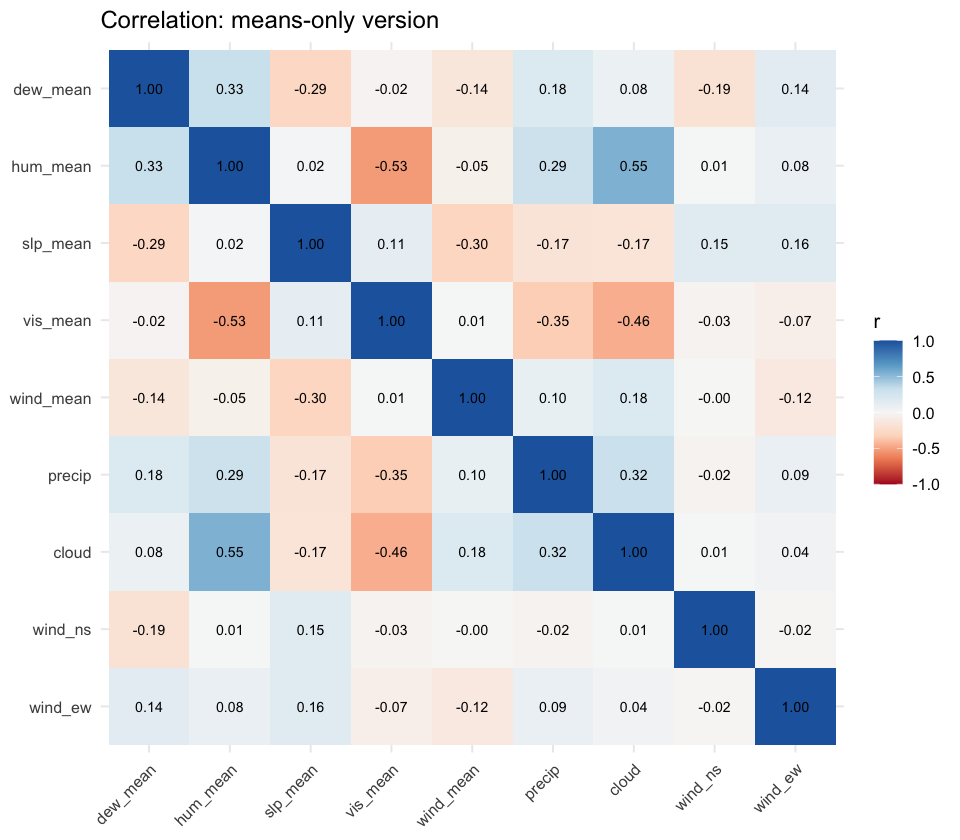

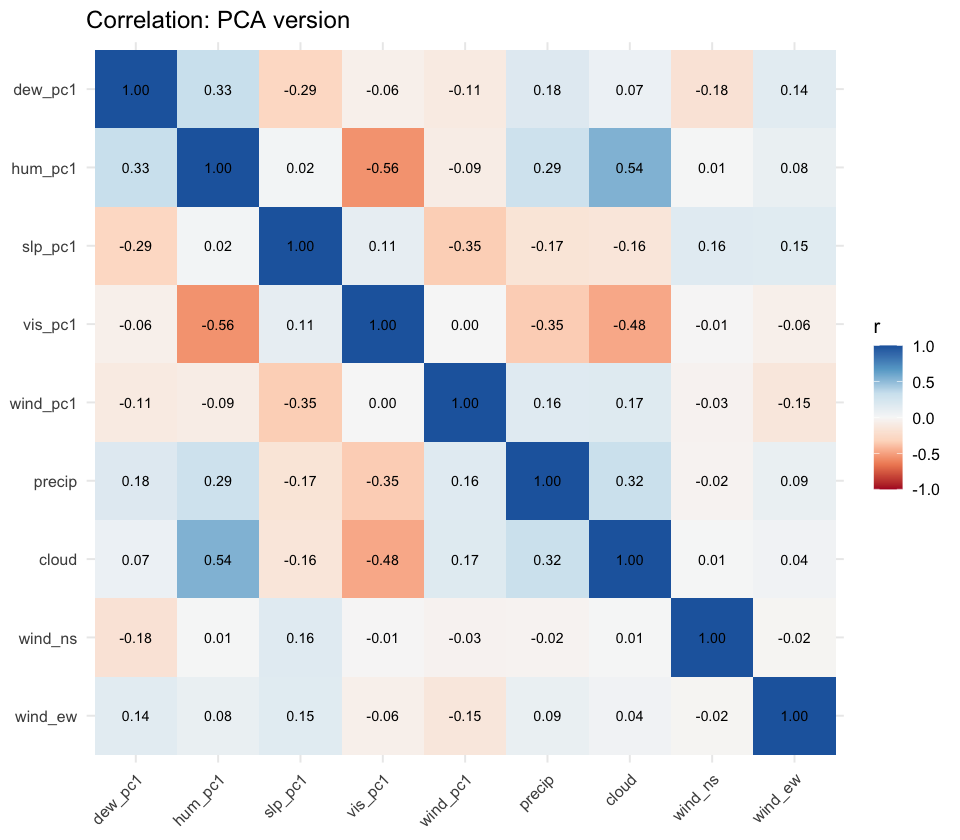

In [47]:
other_vars <- c("precip", "cloud", "wind_ns", "wind_ew")

mean_version <- collin_df |> select(all_of(reduced_vars))
pca_version  <- map(family_pca, "score") |>
  as_tibble() |>
  rename_with(\(x) paste0(x, "_pc1")) |>
  bind_cols(select(collin_df, all_of(other_vars)))

same_rows <- complete.cases(mean_version) & complete.cases(pca_version)
cat("Airport-days used for both versions:", sum(same_rows), "of", nrow(collin_df), "\n")

R_mean <- cor(mean_version[same_rows, ])
R_pca  <- cor(pca_version[same_rows, ])

plot_cor <- function(R, title) {
  as_tibble(R, rownames = "v1") |>
    pivot_longer(-v1, names_to = "v2", values_to = "r") |>
    mutate(v1 = factor(v1, colnames(R)), v2 = factor(v2, rev(colnames(R)))) |>
    ggplot(aes(v1, v2, fill = r)) +
    geom_tile() +
    geom_text(aes(label = sprintf("%.2f", r)), size = 3) +
    scale_fill_distiller(palette = "RdBu", limits = c(-1, 1), direction = 1) +
    labs(x = NULL, y = NULL, title = title) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

fig(8, 7)
print(plot_cor(R_mean, "Correlation: means-only version"))
print(plot_cor(R_pca,  "Correlation: PCA version"))

In [48]:
fig()
vif_mean <- diag(solve(R_mean))
vif_pca  <- diag(solve(R_pca))

# Line the two versions up by family (dew_mean <-> dew_pc1, etc.; shared variables match themselves)
family_of <- \(v) str_remove(v, "_(mean|pc1)$")

cat("VIF for each variable, side by side:\n")
left_join(
  tibble(family = family_of(names(vif_mean)), means_var = names(vif_mean), vif_means = vif_mean),
  tibble(family = family_of(names(vif_pca)),  pca_var   = names(vif_pca),  vif_pca   = vif_pca),
  by = "family"
) |>
  mutate(across(starts_with("vif"), \(x) round(x, 2))) |>
  arrange(desc(vif_means)) |>
  print(n = Inf)

off_diag <- \(R) abs(R[upper.tri(R)])
cat("\nOverall comparison:\n")
tibble(
  version         = c("means only", "PCA"),
  max_abs_cor     = round(c(max(off_diag(R_mean)), max(off_diag(R_pca))), 3),
  pairs_abs_r_0.5 = c(sum(off_diag(R_mean) > 0.5), sum(off_diag(R_pca) > 0.5)),
  max_vif         = round(c(max(vif_mean), max(vif_pca)), 2),
  mean_vif        = round(c(mean(vif_mean), mean(vif_pca)), 2)
)

VIF for each variable, side by side:
# A tibble: 9 × 5
  family  means_var vif_means pca_var  vif_pca
  <chr>   <chr>         <dbl> <chr>      <dbl>
1 hum     hum_mean       2.13 hum_pc1     2.15
2 cloud   cloud          1.7  cloud       1.69
3 vis     vis_mean       1.67 vis_pc1     1.72
4 dew     dew_mean       1.54 dew_pc1     1.49
5 slp     slp_mean       1.44 slp_pc1     1.46
6 precip  precip         1.24 precip      1.26
7 wind    wind_mean      1.23 wind_pc1    1.28
8 wind_ew wind_ew        1.09 wind_ew     1.09
9 wind_ns wind_ns        1.05 wind_ns     1.05

Overall comparison:


version,max_abs_cor,pairs_abs_r_0.5,max_vif,mean_vif
<chr>,<dbl>,<int>,<dbl>,<dbl>
means only,0.549,2,2.13,1.45
PCA,0.561,2,2.15,1.46


# Target-airport subset

The 15 airports we will be scored on. `weather_cleaned` keeps all 98 airports, since the others may still be useful as predictors.

In [49]:
target_airports <- c("ABQ", "ATL", "BOS", "DEN", "DFW", "DLH", "DTW", "EYW",
                     "IAD", "LAN", "LAX", "SEA", "SFO", "SLC", "TVC")
stopifnot(all(target_airports %in% airports))

weather_cleaned_subset <- weather_cleaned |>
  filter(airport %in% target_airports)

cat(n_distinct(weather_cleaned_subset$airport), "airports,", nrow(weather_cleaned_subset), "airport-days\n\n")
cat("Missing temperature values per target airport after cleaning:\n")
weather_cleaned_subset |>
  group_by(airport) |>
  summarise(across(all_of(temp_cols), \(x) sum(is.na(x)), .names = "na_{.col}")) |>
  print(n = Inf)

15 airports, 54780 airport-days

Missing temperature values per target airport after cleaning:
# A tibble: 15 × 4
   airport na_tmax na_tmean na_tmin
   <chr>     <int>    <int>   <int>
 1 ABQ           0        0       0
 2 ATL           0        0       0
 3 BOS           0        0       0
 4 DEN           1        0       1
 5 DFW           0        0       0
 6 DLH           0        0       0
 7 DTW           0        1       0
 8 EYW           1        2       2
 9 IAD           0        1       0
10 LAN           0        0       0
11 LAX           0        0       0
12 SEA           0        0       0
13 SFO           0        0       0
14 SLC           1        0       0
15 TVC           1        1       1


## Save
Write the cleaned tables, the cleaning log and the list of temperature spikes to `data/weather_clean.rda` for later notebooks.

In [50]:
save(weather_cleaned, weather_cleaned_subset, target_airports, airports, clean_log, temp_spikes,
     file = "../data/weather_clean.rda")
cat("Saved ../data/weather_clean.rda\n")

Saved ../data/weather_clean.rda


## Notes
